# MeltHEAs: rule-of-mixtures regression on ResultsDB

This notebook reproduces the MeltHEAs analysis I ran through [AURAMCP](https://nanohub.org/tools/auramcp)
around **July 17, 2026** during SURF. AURAMCP was built by Juan Carlos Verduzco, Daniel Mejia, and Mohnish
Harwani. My part was running and validating the workflow.

**The question.** `meltheas` is a nanoHUB Sim2L for LAMMPS solid–liquid coexistence on Cr–Co–Cu–Fe–Ni
high-entropy alloys. Each run needs a starting `Tsolid` (with `Tliquid`) close enough to the melting point to
reach coexistence. Can a simple composition model, fit to past successful runs, predict a good `Tsolid` for a
composition that has never been run?

**Workflow (as run through AURAMCP):**
1. `get_tool_metadata("meltheas")` for the field names
2. `get_data_from_nanohub`: 2,000 runs, filtered on `Coexistence == 1` and `Converged == 1`
3. Fit models on composition → `Tsolid`
4. `find_novel_datapoints`: a composition with 0 existing runs
5. `run_sim2l` at the predicted temperatures to check it live

**Results reported in July** (the targets for this reproduction):

| | value |
|---|---|
| model | no-intercept linear regression (rule of mixtures) |
| test R² / MAE / RMSE | 0.983 / 19.2 K / 23.3 K, n_test = 400 |
| Ridge, polynomial, RF, GB | no better |
| novel composition | Cr0.15 Co0.15 Cu0.35 Fe0.15 Ni0.20 (0 existing points) |
| live run | Tm = 1891.7 ± 1.8 K; 47.5 % solid / 50.7 % liquid |
| squid | `meltheas/r61/351eb53859acc7b58312de6e6e472ef76f5a33f0` |

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

DATA, FIGS = Path("data"), Path("figures")
ELEMENTS = ["Cr", "Co", "Cu", "Fe", "Ni"]
X_COLS = [f"input.composition{i}" for i in range(1, 6)]
Y_COL = "input.Tsolid"
SEED = 42  # reproduces the July test metrics exactly (section 3)

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#d9822b", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
})

## 1. Load the July ResultsDB pull

`data/meltheas_runs_jul17.csv` is the table AURAMCP's `get_data_from_nanohub` returned on July 17: 2,000
runs, already filtered on `Coexistence == 1` and `Converged == 1`, so those two columns aren't in it.

To pull fresh data, run `python fetch_resultsdb.py` (credentials from `.env`) and set `USE_FRESH = True`.
ResultsDB sorts by newest revision first, so a fresh pull may include runs added after July, and the
numbers below will shift.

In [2]:
USE_FRESH = False

if USE_FRESH:
    raw = pd.read_csv(DATA / "meltheas_runs.csv")
    raw = raw[(raw["output.Coexistence"] == 1) & (raw["output.Converged"] == 1)]
else:
    raw = pd.read_csv(DATA / "meltheas_runs_jul17.csv")

print(raw.shape)
print("runs per tool revision:", raw["revision"].value_counts().sort_index().to_dict())
raw.head()

(2000, 14)
runs per tool revision: {39: 1552, 42: 10, 44: 13, 53: 193, 54: 232}


,squid,revision,date,input.composition1,input.composition2,input.composition3,input.composition4,input.composition5,input.Tsolid,input.Tliquid,output.melting_temperature,output.melting_temperature_ci,output.fraction_solid,output.fraction_liquid
0,meltheas/r39/56e11a0cf30d6b27d25462f069dc1c83f...,39,2021-09-01 14:01:18.979085,0.1,0.0,0.0,0.5,0.4,1591.437851,3182.875703,2460.416126,2.700152,0.396918,0.587240
1,meltheas/r39/80a1d46663b77d4c7ea71566b5dcec4e8...,39,2021-09-01 15:05:28.315891,0.1,0.0,0.0,0.5,0.4,1587.459257,3174.918513,2473.705994,2.427769,0.446832,0.540148
2,meltheas/r39/04d4ae172912c0c1a5a752109501d4fa7...,39,2021-09-01 18:06:52.992838,0.1,0.0,0.0,0.5,0.4,1589.242475,3178.484951,2451.804087,2.629795,0.468750,0.514540
3,meltheas/r39/58153bf41fe2ba02d5da31ea7dbe33dca...,39,2021-09-01 20:16:54.773166,0.2,0.0,0.4,0.2,0.2,1207.103589,2414.207177,1846.231777,1.894653,0.444444,0.547309
4,meltheas/r39/43dfb274cf0ed12b06baf6e39e092f7a4...,39,2021-09-01 22:58:55.589825,0.1,0.4,0.0,0.4,0.1,1517.457703,3034.915406,2389.329413,2.448105,0.554036,0.430556


## 2. Sanity checks

Every run should have compositions summing to 1 and solid/liquid fractions inside the 35–65 %
coexistence window. `Tliquid` is set to 2 × `Tsolid` by convention, so it adds nothing as a separate target.

In [3]:
comp_sum = raw[X_COLS].sum(axis=1)
print(f"composition sums: {comp_sum.min():.4f} to {comp_sum.max():.4f}")
for c in ["output.fraction_solid", "output.fraction_liquid"]:
    print(f"{c}: {raw[c].min():.3f} to {raw[c].max():.3f}")

ratio = raw["input.Tliquid"] / raw[Y_COL]
print("\nTliquid / Tsolid, rounded:")
print(ratio.round(3).value_counts().to_string())

composition sums: 1.0000 to 1.0020
output.fraction_solid: 0.350 to 0.639
output.fraction_liquid: 0.350 to 0.638

Tliquid / Tsolid, rounded:
2.000    1829
1.999     128
2.008      37
2.007       4
2.400       1
2.001       1


All but one run have a ratio of 2 to within 0.01. The small offsets (1.999, 2.008) come from inputs stored
with fewer digits. The exception is a pure-Cr run with `Tsolid` = 1090 K and `Tliquid` = 2616 K
(ratio 2.4). The July fit dropped this run, leaving **1,999** rows, and so does this notebook.

In [4]:
print(raw[(ratio - 2).abs() > 0.01][["squid", *X_COLS, "input.Tsolid", "input.Tliquid"]].to_string(index=False))

df = raw[(ratio - 2).abs() <= 0.01].reset_index(drop=True)
print(f"\n{len(df)} runs kept")

                                                squid  input.composition1  input.composition2  input.composition3  input.composition4  input.composition5  input.Tsolid  input.Tliquid
meltheas/r39/edee49f5fcb67d3f2a8f60ae105f5d1325f1980d                 1.0                 0.0                 0.0                 0.0                 0.0        1090.0         2616.0

1999 runs kept


## 3. Rule-of-mixtures fit

With no intercept and fractions that sum to 1, the linear model reads as a rule of mixtures: each
coefficient is that element's effective `Tsolid` contribution in kelvin. These coefficients are empirical
fits, not pure-element melting points.

In [5]:
X, y = df[X_COLS].to_numpy(), df[Y_COL].to_numpy()
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED)

def scores(y_true, y_pred):
    return {"R2": r2_score(y_true, y_pred),
            "MAE_K": mean_absolute_error(y_true, y_pred),
            "RMSE_K": mean_squared_error(y_true, y_pred) ** 0.5}

rom = LinearRegression(fit_intercept=False).fit(X_tr, y_tr)
rom_test = scores(y_te, rom.predict(X_te))
print(f"n_train={len(y_tr)}  n_test={len(y_te)}")
print(f"test R2 {rom_test['R2']:.4f}  MAE {rom_test['MAE_K']:.2f} K  RMSE {rom_test['RMSE_K']:.2f} K")
print("July:   R2 0.983   MAE 19.2 K   RMSE 23.3 K   (n_test=400)")

n_train=1599  n_test=400
test R2 0.9831  MAE 19.19 K  RMSE 23.29 K
July:   R2 0.983   MAE 19.2 K   RMSE 23.3 K   (n_test=400)


The metrics come from the 80/20 split. The model saved on July 17 (`meltheas_Tsolid_model.pkl`, exported to
`data/reference_model_jul17.json`) was then **refit on all 1,999 runs**. Refitting here recovers its
coefficients:

In [6]:
ref = json.loads((DATA / "reference_model_jul17.json").read_text())
rom_full = LinearRegression(fit_intercept=False).fit(X, y)

coef = pd.DataFrame({
    "split_fit_K": rom.coef_,
    "full_fit_K": rom_full.coef_,
    "jul17_saved_K": [ref["coef_K"][e] for e in ELEMENTS],
}, index=ELEMENTS)
coef["full_minus_saved_K"] = coef["full_fit_K"] - coef["jul17_saved_K"]
coef.round(3)

,split_fit_K,full_fit_K,jul17_saved_K,full_minus_saved_K
Cr,1252.891,1252.177,1252.177,-0.0
Co,1426.634,1424.962,1424.962,0.0
Cu,783.357,783.877,783.877,-0.0
Fe,1742.415,1743.071,1743.071,-0.0
Ni,1425.701,1426.879,1426.879,0.0


## 4. Do more flexible models help?

In July, Ridge, degree-2 polynomial, random forest, and gradient boosting were compared with 5-fold
cross-validation. None did better than the rule of mixtures. Below are the held-out test scores and 5-fold CV
RMSE on the full 1,999 runs.

In [7]:
models = {
    "Rule of mixtures (linear, no intercept)": LinearRegression(fit_intercept=False),
    "Ridge (alpha=1, no intercept)": Ridge(alpha=1.0, fit_intercept=False),
    # fractions sum to 1, so the degree-2 terms are exactly collinear; plain least squares blows up on
    # some CV folds, and a tiny ridge penalty keeps it well-conditioned
    "Polynomial deg 2 (ridge alpha=1e-3)": make_pipeline(PolynomialFeatures(2, include_bias=False), Ridge(alpha=1e-3)),
    "Random forest": RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1),
    "Gradient boosting": GradientBoostingRegressor(random_state=SEED),
}
cv = KFold(5, shuffle=True, random_state=SEED)
rows, fitted = {}, {}
for name, m in models.items():
    fitted[name] = m.fit(X_tr, y_tr)
    row = scores(y_te, m.predict(X_te))
    row["CV5_RMSE_K"] = -cross_val_score(m, X, y, cv=cv, scoring="neg_root_mean_squared_error").mean()
    rows[name] = row
comparison = pd.DataFrame(rows).T.sort_values("CV5_RMSE_K")
comparison.round(3)

,R2,MAE_K,RMSE_K,CV5_RMSE_K
Polynomial deg 2 (ridge alpha=1e-3),0.983,19.224,23.205,23.419
"Rule of mixtures (linear, no intercept)",0.983,19.191,23.289,23.570
Gradient boosting,0.982,19.360,23.865,23.663
"Ridge (alpha=1, no intercept)",0.982,19.779,23.833,24.150
Random forest,0.979,20.644,26.275,25.764


All five models land within about 2 K of each other in CV RMSE. The regularized quadratic comes out ahead by
roughly 0.2 K, which is well within the fold-to-fold scatter and uses 20 terms instead of 5. The extra
flexibility doesn't buy real accuracy, so the five-coefficient linear model is the one to use: it is
interpretable, and it extrapolates smoothly to compositions with no nearby training points.

## 5. Parity plots

**The poster figure is not this model.** The parity plot used on the poster
(`figures/poster_rf_parity_jul17.png`) is titled *Random Forest* and shows test R² 0.981 / MAE 19.7 K. The metrics
reported on the poster (R² 0.983 / MAE 19.2 K / RMSE 23.3 K) are from the rule-of-mixtures linear model. The
figure below is the linear model. Use it if the figure should match the reported numbers.

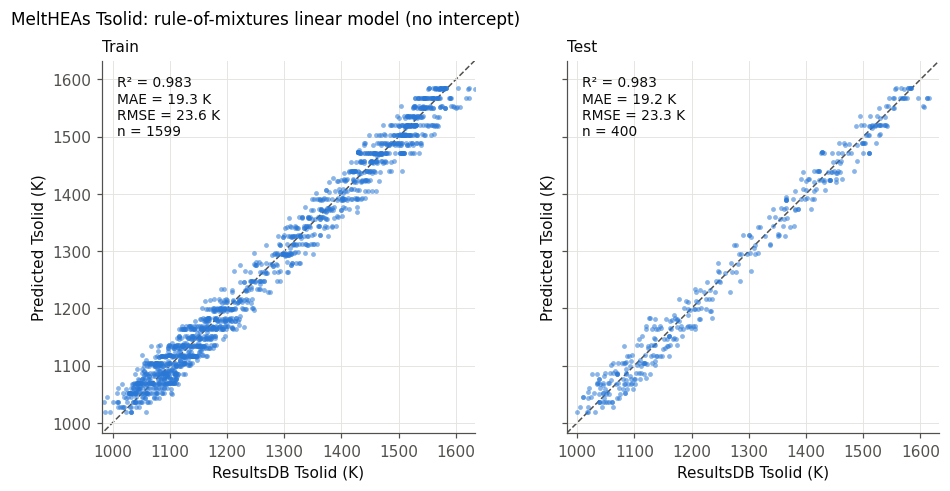

In [8]:
def parity(ax, y_true, y_pred, title):
    lo, hi = min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())
    pad = 0.03 * (hi - lo)
    ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], color=MUTED, lw=1, ls="--", zorder=1)
    ax.scatter(y_true, y_pred, s=10, color=BLUE, alpha=0.55, linewidths=0, zorder=2)
    s = scores(y_true, y_pred)
    ax.text(0.04, 0.96, f"R² = {s['R2']:.3f}\nMAE = {s['MAE_K']:.1f} K\nRMSE = {s['RMSE_K']:.1f} K\nn = {len(y_true)}",
            transform=ax.transAxes, va="top", fontsize=9, color=INK)
    ax.set(xlim=(lo - pad, hi + pad), ylim=(lo - pad, hi + pad), aspect="equal",
           xlabel="ResultsDB Tsolid (K)", ylabel="Predicted Tsolid (K)")
    ax.set_title(title, fontsize=10, color=INK, loc="left")

fig, axes = plt.subplots(1, 2, figsize=(9, 4.4), sharex=True, sharey=True)
parity(axes[0], y_tr, rom.predict(X_tr), "Train")
parity(axes[1], y_te, rom.predict(X_te), "Test")
fig.suptitle("MeltHEAs Tsolid: rule-of-mixtures linear model (no intercept)", x=0.02, ha="left", fontsize=11)
fig.tight_layout()
FIGS.mkdir(exist_ok=True)
fig.savefig(FIGS / "parity_rule_of_mixtures.png", dpi=200, bbox_inches="tight")

Test residuals by composition show whether any region of composition space is systematically off:

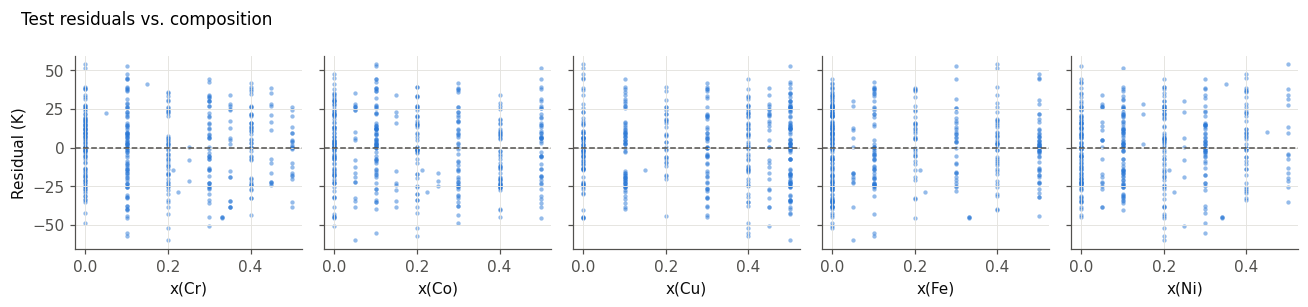

In [9]:
resid = y_te - rom.predict(X_te)
fig, axes = plt.subplots(1, 5, figsize=(12, 2.8), sharey=True)
for i, (ax, el) in enumerate(zip(axes, ELEMENTS)):
    ax.axhline(0, color=MUTED, lw=1, ls="--")
    ax.scatter(X_te[:, i], resid, s=8, color=BLUE, alpha=0.5, linewidths=0)
    ax.set_xlabel(f"x({el})")
axes[0].set_ylabel("Residual (K)")
fig.suptitle("Test residuals vs. composition", x=0.02, ha="left", fontsize=11)
fig.tight_layout()

## 6. Novel composition and live run

`find_novel_datapoints` returned **Cr0.15 Co0.15 Cu0.35 Fe0.15 Ni0.20**, a composition with 0 existing
ResultsDB points. The saved July model predicts `Tsolid`, and `Tliquid` follows the 2× convention.
`meltheas_temperature_predictor.py` in this folder is the standalone version of the model that was used to
pick the inputs.

In [10]:
from meltheas_temperature_predictor import predict_temperatures

novel = dict(zip(ELEMENTS, [0.15, 0.15, 0.35, 0.15, 0.20]))
t_solid, t_liquid = predict_temperatures(novel)
print(f"Tsolid = {t_solid:.1f} K, Tliquid = {t_liquid:.1f} K  (predictor script, Jul 17 coefficients)")

x_novel = np.array([list(novel.values())])
print(f"Tsolid = {rom_full.predict(x_novel)[0]:.1f} K                     (refit in this notebook)")

# nearest training compositions, to show this is interpolation rather than extrapolation
dist = np.linalg.norm(X - x_novel, axis=1)
near = df.assign(dist=dist).nsmallest(5, "dist")[[*X_COLS, Y_COL, "output.melting_temperature", "dist"]]
near.round(3)

Tsolid = 1222.8 K, Tliquid = 2445.5 K  (predictor script, Jul 17 coefficients)
Tsolid = 1222.8 K                     (refit in this notebook)


,input.composition1,input.composition2,input.composition3,input.composition4,input.composition5,input.Tsolid,output.melting_temperature,dist
18,0.2,0.1,0.4,0.1,0.2,1183.354,1782.384,0.1
57,0.2,0.1,0.4,0.1,0.2,1137.807,1776.613,0.1
906,0.1,0.2,0.4,0.1,0.2,1126.329,1781.332,0.1
920,0.1,0.2,0.4,0.1,0.2,1168.042,1788.941,0.1
1038,0.1,0.2,0.4,0.1,0.2,1167.725,1796.319,0.1


The live `run_sim2l` job (squid `meltheas/r61/351eb53859acc7b58312de6e6e472ef76f5a33f0`) gave:

- **Tm = 1891.7 ± 1.8 K** (`melting_temperature` ± `melting_temperature_ci`)
- **47.5 % solid / 50.7 % liquid**, inside the 35–65 % coexistence window, so the run counts as successful

The model's job was to choose starting temperatures that reach coexistence on the first try, and the live run
did. `Tsolid` is a simulation input, not a melting-point estimate, so it should not be compared
number-for-number with Tm.

**TODO**
- [ ] Pull the r61 run's outputs by squid and plot its temperature / phase-fraction series